# Start year and keyword candidates from scientific literature

**Innovation Management · PW · Team 2 · Flying drones (client: Leonardo)**

This notebook supports two Step 0 decisions with evidence from scientific publications (not patents):

1. **Start year of the analysis window**: when does research on UAVs "take off"? We count publications per year in two independent databases, **OpenAlex** and **Scopus**, for four search terms.
2. **Keyword candidates for the PATSTAT query**: which terms do the most-cited UAV papers use, and does the vocabulary change over time?

**Window agreed with the prof:** earliest filing year up to **2022-2023** (later years are incomplete because of the publication lag).

**Folders used:** `csv/` for input and output tables, `figures/` for charts.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | OpenAlex: publications per year by search term |
| 3 | Scopus: publications per year by search term |
| 4 | Scopus: keyword extraction from top-cited papers |
| 5 | Keyword vocabulary over time (heatmap) |

## 1. Setup

In [3]:
# Libraries for the OpenAlex API (requests) and tables (pandas)
import requests
import pandas as pd

## 2. OpenAlex: publications per year by search term

[OpenAlex](https://openalex.org) is a free, open database of scholarly works with a public API. For each of the four search terms we ask the API for the **number of publications per year** (`group_by=publication_year`) instead of downloading the papers themselves.

**Filters**, chosen to make OpenAlex comparable to our Scopus search:

| Filter | Why |
|---|---|
| `title_and_abstract.search` | Search only title and abstract (the default search also looks in full text, which is looser) |
| `type:article\|review` | Research papers only; OpenAlex labels most conference papers as "article" |
| `language:en` | English only, like our PATSTAT keyword search |
| `publication_year:1950-2025` | Removes obvious date errors (e.g. records dated 1765 or 2027) |
| `is_paratext:false` | Removes front matter, tables of contents, etc. |

**Known limitation:** OpenAlex has metadata gaps (e.g. about 40% of records lack an abstract) and fuzzy matching, so counts are **indicative**; we rely on the *timing* of the take-off, not on exact numbers (Borrego & Urbano, 2025, arXiv:2512.16434).

The result is saved to `csv/openalex_terms_all_years.csv`: one row per year, one column per term.

In [11]:
# Query OpenAlex once per search term and collect the number of publications per year
# The quotes inside each term ask for the exact phrase
terms = ['"unmanned aerial vehicle"', '"UAV"', '"drone"', '"unmanned aircraft"']
OPENALEX_API_KEY="JLmen6mrH6aXDKw85VGTXe"  # optional, but increases the rate limit

tables = {}
for t in terms:
    params = {
        "filter": ",".join([
            f"title_and_abstract.search:{t}",
            "type:article|review",          # OpenAlex files most conference papers as "article"
            "language:en",
            "publication_year:1950-2025",
            "is_paratext:false",            # drop front matter, tables of contents, etc.
        ]),
        "group_by": "publication_year",
    }
    if OPENALEX_API_KEY:
        params["api_key"] = OPENALEX_API_KEY
    r = requests.get("https://api.openalex.org/works", params=params).json()
    d = pd.DataFrame(r["group_by"]).astype({"key": int}).set_index("key")["count"]
    tables[t.strip('"')] = d
    
# one table, all years, one column per term
all_years = pd.DataFrame(tables).fillna(0).astype(int).sort_index()
all_years.to_csv("csv/openalex_terms_all_years.csv")
all_years

,unmanned aerial vehicle,UAV,drone,unmanned aircraft
key,,,,
1950,1,1,2,0
1951,0,0,5,0
1952,0,0,2,0
1953,0,0,4,1
1954,0,0,1,0
...,...,...,...,...
2021,5344,5907,3539,417
2022,5890,6893,3742,341
2023,6667,7900,4442,358


### 2.1 Chart: OpenAlex publications per year (log scale)

- **Log scale**: makes steady growth look like a straight line and keeps small early counts visible.`
- **Grey area (before 2000)** and **orange area (after 2022)**: years outside our analysis window.
- **Red dashed line**: proposed start year, 2000.

In [12]:
import matplotlib.pyplot as plt

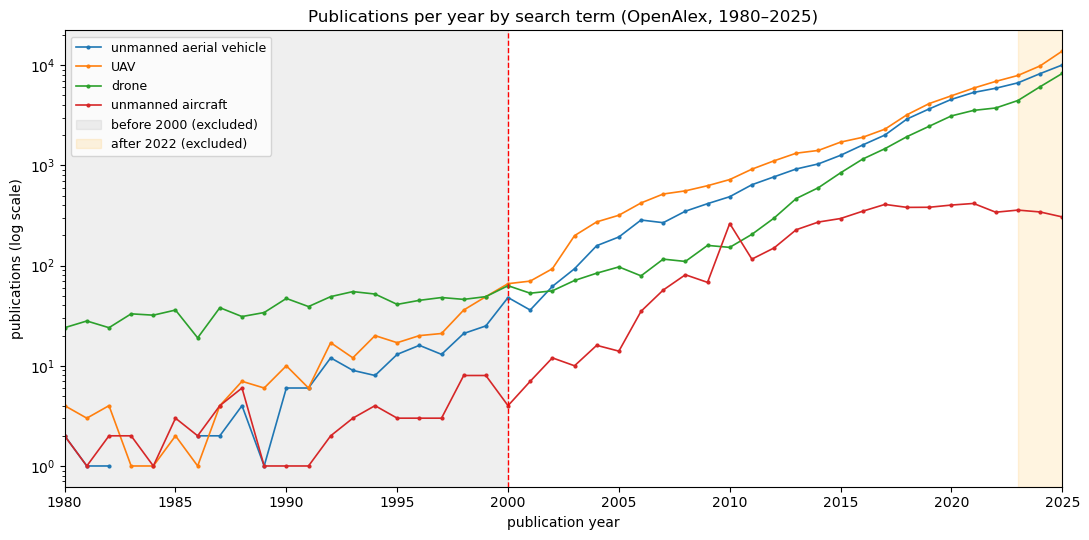

In [13]:
# Plot publications per year for each search term (OpenAlex)
all_years.columns = [c.strip('"') for c in all_years.columns]      # remove the extra quotes in the column names

fig, ax = plt.subplots(figsize=(11, 5.5))
for term in all_years.columns:
    ax.plot(all_years.index, all_years[term].replace(0, float("nan")),   # skip zeros (log scale can't show 0)
            marker="o", ms=2, lw=1.2, label=term)

ax.set_yscale("log")
ax.set_xlim(1980, 2025)
ax.axvspan(all_years.index.min(), 2000, color="grey", alpha=0.12, label="before 2000 (excluded)")
ax.axvspan(2023, all_years.index.max(), color="orange", alpha=0.12, label="after 2022 (excluded)")
ax.axvline(2000, color="red", ls="--", lw=1)

ax.set(title="Publications per year by search term (OpenAlex, 1980–2025)",
       xlabel="publication year", ylabel="publications (log scale)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("figures/openalex_terms_all_years.png", dpi=200)
plt.show()

## 3. Scopus: publications per year by search term

Scopus is a curated, subscription database (accessed through PoliTo). It is used as an **independent check** of the OpenAlex take-off.

**How the input files were made (manually, in Scopus):**
1. Advanced search, e.g. `TITLE-ABS-KEY("unmanned aerial vehicle") AND PUBYEAR > 1979 AND PUBYEAR < 2026`
2. *Analyze search results* → *Documents by year* → *Export* to CSV
3. Repeated for each of the four terms → files `csv/Scopus-10-Analyze-Year*.csv`

Each export has a few lines of text before the data (title, query, number of results, a `"YEAR"` header). The function below reads the **search term** from the query line and keeps only the numeric year/count rows.

In [14]:
# Path handling for the input folder
from pathlib import Path

In [15]:
# Read one Scopus 'Analyze year' export -> (search term, publications per year)
import re

def read_scopus(path):
    """Read a Scopus 'Analyze year' export: returns (search term, Series year -> count)."""
    lines = Path(path).read_text(encoding="utf-8-sig").splitlines()
    query = next(l for l in lines if "Your query" in l)
    term = re.search(r'TITLE-ABS-KEY\(""(.+?)""\)', query).group(1)

    data = pd.read_csv(path, skiprows=5, header=None, usecols=[0, 1], names=["year", "count"])
    data["year"] = pd.to_numeric(data["year"], errors="coerce")     # "YEAR" and other text become NaN
    data["count"] = pd.to_numeric(data["count"], errors="coerce")
    data = data.dropna().astype(int)                                  # keep only real rows
    return term, data.set_index("year")["count"].sort_index()

### 3.1 Load all four Scopus exports into one table
One column per search term, one row per year. The two printed checks confirm the parsing worked: the index must be numeric (`int64`), and the text row `"YEAR"` must be gone.

In [16]:
# Folder with the CSV exports (relative to this notebook)
# Load every Scopus year export in the folder and combine them: one column per term
folder = Path("csv/")      # "." means: the same folder as the notebook
scopus = dict(read_scopus(f) for f in sorted(folder.glob("Scopus-10-Analyze-Year*.csv")))
df_scopus = pd.DataFrame(scopus).fillna(0).astype(int)
print(df_scopus.index.dtype)      # should be int64, not object
df_scopus.tail()                  # the "YEAR" row should be gone

int64


,unmanned aerial vehicle,drone,UAV,unmanned aircraft
year,,,,
2021,10524,5794,10536,598
2022,12192,6123,12301,545
2023,14435,7401,14771,533
2024,16719,9689,17682,575
2025,20027,12564,22664,465


### 3.2 Chart: Scopus publications per year (log scale)

Same layout as the OpenAlex chart, so the two can be compared side by side. Scopus counts are lower overall (more selective coverage); only the **shape** and **timing** matter.

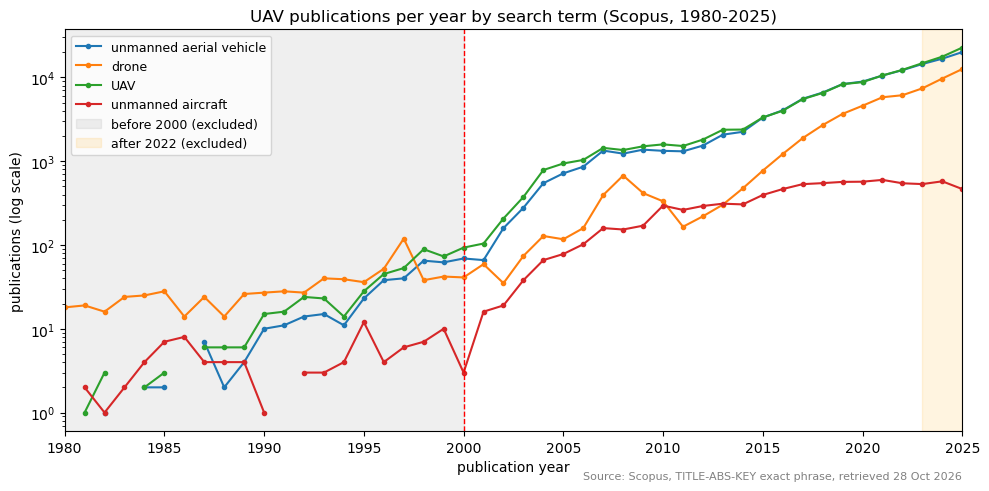

In [17]:
# Plot publications per year for each search term (Scopus)
fig, ax = plt.subplots(figsize=(10, 5))
for term in df_scopus.columns:
    ax.plot(df_scopus.index, df_scopus[term].replace(0, float("nan")), marker="o", ms=3, label=term)

ax.set_yscale("log")
ax.set_xlim(1980, 2025)
ax.axvspan(1980, 2000, color="grey", alpha=0.12, label="before 2000 (excluded)")
ax.axvspan(2023, df_scopus.index.max(), color="orange", alpha=0.12, label="after 2022 (excluded)")
ax.axvline(2000, color="red", ls="--", lw=1)
ax.set(title="UAV publications per year by search term (Scopus, 1980-2025)",
       xlabel="publication year", ylabel="publications (log scale)")
ax.legend(fontsize=9)
ax.text(1.0, -0.12, "Source: Scopus, TITLE-ABS-KEY exact phrase, retrieved 28 Oct 2026",
        transform=ax.transAxes, ha="right", fontsize=8, color="grey")
plt.tight_layout()
plt.savefig("figures/scopus_terms.png", dpi=200)
plt.show()

## 4. Keyword extraction from top-cited Scopus papers

**Goal:** find which terms the research community uses for flying drones, as **candidate keywords** for the PATSTAT query.

**How the input files were made (manually, in Scopus):**
- One combined query for the four terms, with "drone" restricted to aircraft contexts:
  `TITLE-ABS-KEY ( "unmanned aerial vehicle" OR "UAV" OR "unmanned aircraft" OR ( "drone" AND ( aerial OR flight OR flying ) ) ) AND PUBYEAR > 1999 AND PUBYEAR < 2024 AND DOCTYPE ( ar OR cp OR re ) AND LANGUAGE ( english ) AND PUBYEAR > 2014 AND PUBYEAR < 2020`
- Filters: articles, conference papers and reviews; English only
- **Top 200 most-cited papers per period** (2000–04, 2005–09, 2010–14, 2015–19, 2020–23), sorted by citations *within* each period so that older papers don't dominate
- Exported fields: Author keywords, Indexed keywords, Document title, Year, Citation count, EID
- Files: `csv/scopus_2000-2004.csv` … `csv/scopus_2020-2023.csv`

### 4.1 Load and combine the five exports

In [18]:
# Load the five period exports into one table of papers
# EID = Scopus unique paper ID, used to remove papers that appear in more than one export
files = sorted(folder.glob("scopus_20*.csv"))
print([f.name for f in files])

papers = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
papers = papers.drop_duplicates("EID")               # same paper in two exports -> once
print(f"{len(papers):,} papers")
papers["Year"].value_counts().sort_index()

['scopus_2000-2004.csv', 'scopus_2005-2009.csv', 'scopus_2010-2014.csv', 'scopus_2015-2019.csv', 'scopus_2020-2023.csv']
952 papers


Year
2000    15
2001    19
2002    30
2003    45
2004    91
2005    19
2006    21
2007    33
2008    48
2009    57
2010    29
2011    24
2012    42
2013    41
2014    38
2015    26
2016    27
2017    41
2018    53
2019    53
2020    80
2021    42
2022    51
2023    27
Name: count, dtype: int64

### 4.2 Count how many papers use each keyword

- Both **author keywords** (chosen by the authors) and **index keywords** (standardised by Scopus) are used.
- Keywords are lower-cased and split on `;` (one row per paper and keyword).
- Each keyword is counted **once per paper**, so the table shows *how many papers use the term*, not how many times it is repeated.
- `% of papers` = share of all papers in the sample that use the keyword.

In [19]:
# Split the keyword fields into one row per (paper, keyword) and count papers per keyword
def split_keywords(col):
    """One row per (paper, keyword), lower-case, trimmed."""
    return (papers[["EID", "Year", col]].dropna()
            .assign(keyword=lambda d: d[col].str.lower().str.split(";"))
            .explode("keyword")
            .assign(keyword=lambda d: d["keyword"].str.strip())
            .query("keyword != ''")[["EID", "Year", "keyword"]])

kw = pd.concat([split_keywords("Author Keywords"), split_keywords("Index Keywords")])

# merge the variants before counting
kw["keyword"] = (kw["keyword"]
                 .str.replace(r"\s*\(.*?\)", "", regex=True)
                 .str.replace(r"vehicles$", "vehicle", regex=True)
                 .str.replace(r"systems$", "system", regex=True)
                 .replace({"drones": "drone", "uavs": "uav"}))

kw = kw.drop_duplicates(["EID", "keyword"])          # count each keyword once per paper

# share of papers that use each keyword
top = (kw.groupby("keyword")["EID"].nunique()
         .sort_values(ascending=False)
         .rename("papers").to_frame())
top["% of papers"] = (top["papers"] / papers["EID"].nunique() * 100).round(1)
top.head(60)

,papers,% of papers
keyword,,
unmanned aerial vehicle,632,66.4
antennas,262,27.5
unmanned vehicle,246,25.8
uav,162,17.0
remote sensing,127,13.3
drone,91,9.6
algorithms,83,8.7
computer simulation,74,7.8
motion planning,72,7.6


### 4.3 Does the vocabulary change over time?

Papers are grouped into the five export periods, and for each of the top 40 keywords we count the papers using it in each period. A term that grows over time (e.g. "drones" after 2015) is newer vocabulary; patents from the early 2000s may still use the older terms, so both should be kept.

In [20]:
# Count papers per keyword in each period (rows = keywords, columns = periods)
# does vocabulary change over time? top keywords by period
kw["period"] = pd.cut(kw["Year"], bins=[1999, 2004, 2009, 2014, 2019, 2023],
                      labels=["2000-04", "2005-09", "2010-14", "2015-19", "2020-23"])
by_period = (kw.groupby(["keyword", "period"], observed=True)["EID"].nunique()
               .unstack(fill_value=0))
by_period.loc[top.head(40).index]

period,2000-04,2005-09,2010-14,2015-19,2020-23
keyword,,,,,
unmanned aerial vehicle,79,130,128,153,142
antennas,4,12,17,90,139
unmanned vehicle,112,40,33,38,23
uav,19,21,34,45,43
remote sensing,8,15,35,39,30
drone,1,2,4,48,36
algorithms,44,17,17,2,3
computer simulation,53,13,8,0,0
motion planning,23,16,8,9,16


### 4.4 Save the keyword candidates
The full ranked list is saved classified automatically with `CORE_PATTERN` / `TYPE_PATTERN`into:
- **core** (defines a flying drone) → PATSTAT perimeter query
- **segment** (a type or use of drone, e.g. quadrotor, delivery) → Step 2 subfields
- **too generic** (e.g. control, optimization) → dropped

In [21]:
CORE_PATTERN = r"\b(uavs?|uas|unmanned aerial|unmanned aircraft|unmanned air|drones?|remotely piloted)\b"
TYPE_PATTERN = r"\b(multi-?rotors?|multi-?copters?|quad-?rotors?|quad-?copters?|hexacopters?|octocopters?)\b"

def classify(keyword):
    if re.search(TYPE_PATTERN, keyword):
        return "segment"                                 # drone types -> Step 2 subfields
    if not re.search(CORE_PATTERN, keyword):
        return "other"
    rest = re.sub(CORE_PATTERN, "", keyword)
    rest = re.sub(r"\b(s|vehicles?|systems?)\b|[()\-\s]", "", rest)
    return "core" if rest == "" else "segment"

top["group"] = top.index.map(classify)
top["group"].value_counts()

group
other      7731
segment     163
core         11
Name: count, dtype: int64

In [22]:
MIN_SHARE = 1.0                                          # keep terms used by at least 1% of papers
core = top[(top["group"] == "core") & (top["% of papers"] >= MIN_SHARE)].index.tolist()
core

['unmanned aerial vehicle',
 'uav',
 'drone',
 'unmanned air vehicle',
 'unmanned aircraft system',
 'unmanned aerial system',
 'uas',
 'unmanned aerial vehicle system']

> ⚠️ **Warning for "uas":** It’s a valid keyword in papers (“unmanned aircraft system”), but don’t use it as a PATSTAT substring. `LIKE '%uas%'` would match inside many unrelated words. Use “unmanned aircraft system” instead

In [23]:
# Save the ranked keyword list (derived table, safe to push to GitHub)
top.to_csv("csv/scopus_keyword_candidates.csv")         # for the team to sort by hand

## 5. Heatmap: share of top-cited papers using each core keyword, by period

Each cell = % of the papers in that period that use the keyword. Percentages (not counts) keep periods comparable even if some periods have fewer papers after removing duplicates.

**Reading it:** dark cells late and pale cells early = a newer term (e.g. "drones" rises to ~22% in 2015–19). This supports keeping **both** older terms (UAV, unmanned aerial vehicle) and newer ones (drone) in the PATSTAT query.

*Note:* singular and plural forms (e.g. "drone" / "drones") are shown as separate rows here; PATSTAT's substring search (`LIKE '%drone%'`) matches both.

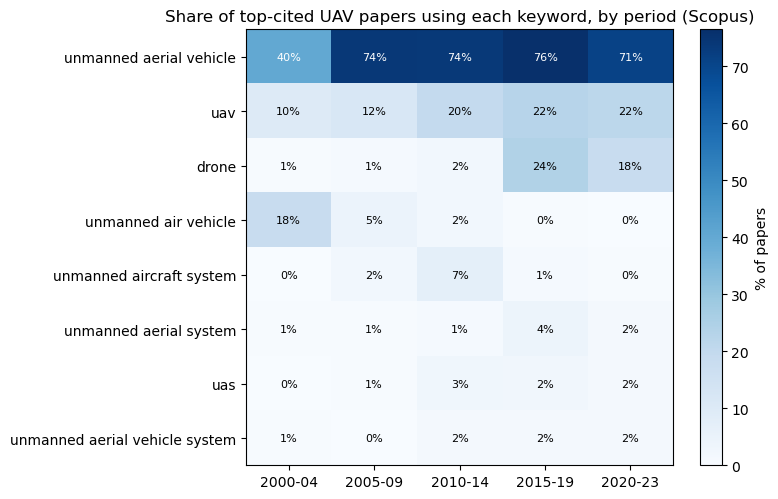

In [24]:
# Heatmap of keyword shares by period
core = [k for k in core if k in by_period.index]     # keep only those found

papers_per_period = kw.groupby("period", observed=True)["EID"].nunique()
share = by_period.loc[core].div(papers_per_period, axis=1) * 100     # % of papers in that period

fig, ax = plt.subplots(figsize=(8, 0.45 * len(core) + 1.5))
im = ax.imshow(share.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(share.shape[1]), share.columns)
ax.set_yticks(range(share.shape[0]), share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, f"{share.values[i, j]:.0f}%", ha="center", va="center", fontsize=8,
                color="white" if share.values[i, j] > share.values.max() / 2 else "black")
ax.set_title("Share of top-cited UAV papers using each keyword, by period (Scopus)")
fig.colorbar(im, ax=ax, label="% of papers")
plt.tight_layout()
plt.savefig("figures/keyword_heatmap.png", dpi=200)
plt.show()

## Summary (for the doc and the appendix)

- **Start year 2000**: in both OpenAlex and Scopus, UAV publications take off around 2000–2003, and earlier years hold only a few percent of publications up to recent ones.
- **"drone" alone is noisy** before 2000 (non-aircraft meanings) → used together with flight-related words, need to validate it on PATSTAT.
- **Vocabulary shift after ~2015**: "drone(s)" becomes common while "UAV" stays steady → keep both.
- **"unmanned aircraft"** is rare in paper keywords but central in the DTI (2019) patent study → keep it for the patent query and test it on PATSTAT.
- These are **candidates** from scientific papers; patents may use different wording, so the final list is decided after testing on PATSTAT.